# Worksheet 3 · Asking, Describing, Constraining, Inferring

**Advanced Methods of AI · WiSe 2026/2027 · the notebook of the tutorial**

Last week you *represented* the pizza world: concepts in description logic, axioms in first-order logic,
the classes of `pizza.owl` as Python dataclasses. Today a robot *uses* that knowledge.

**The story.** Thursday evening in a small pizzeria in Bremen. A service robot works between the counter
and the tables. Seven pizzas are on the counter, three tables have ordered, and two guests must not eat
certain things. Everything the robot does tonight starts with one kind of expression, a *description*,
and the evening shows four things you can do with it:

| Act | The robot … | The description is … |
|:--|:--|:--|
| 1 | **asks** which pizzas have cheese | a *question*: which objects fit? |
| 2 | is told to bring *the* pizza with olives | a *reference*: which one object is meant? |
| 3 | must keep Ben away from milk | a *constraint*: nothing may fit |
| 4 | writes warnings and menu labels | the *condition of a rule*: for everything that fits, conclude … |
| 5 | gets an order for a pizza that does not exist yet | a *specification*: make something that fits |

**How to work.** Run the cells from top to bottom. Cells marked `TODO` are yours; every cell runs as it
is, so you can always continue. Before every cell marked **Predict**, write your prediction on the
worksheet. Every answer is also drawn: the robot's picture of the pizzeria, with the answers ringed in
magenta.

## Prologue · The world the robot knows

The classes are those of `pizza.owl`, as in Worksheet 2. New are `Guest` and `Order`, because a
pizzeria needs to know who gets what. **Run the next three cells; do not edit them.**

In [1]:
from __future__ import annotations

from dataclasses import dataclass, field
from enum import Enum

from IPython.display import SVG, display

from krrood.entity_query_language.backends import (
    EntityQueryLanguageBackend, EntityQueryLanguageGenerativeBackend,
)
from krrood.entity_query_language.exceptions import MultipleSolutionFound, NoSolutionFound
from krrood.entity_query_language.factories import (
    a, an, the, variable, flat_variable, entity, set_of,
    or_, not_, exists, for_all, contains, HasType,
    inference, deduced_variable, add, refinement, alternative,
)
from krrood.entity_query_language.predicate import Predicate, symbolic_function
from krrood.entity_query_language.verbalization.vocabulary.english import Prepositions
from krrood.entity_query_language.verbalization.vocabulary.parts_of_speech import (
    Adjective, Copula, Noun, clause,
)

from kitchen_picture import Colour, KitchenPicture, legend_svg

In [2]:
class Spiciness(Enum):
    MILD = 1
    MEDIUM = 2
    HOT = 3


class Allergen(Enum):
    # Three of the fourteen allergens a restaurant in the EU has to declare.
    GLUTEN = "gluten"
    MILK = "milk"
    FISH = "fish"


# ---- toppings: the class hierarchy of pizza.owl ----

@dataclass(eq=False, repr=False)
class PizzaTopping:
    spiciness: Spiciness = Spiciness.MILD

    def __repr__(self):
        return type(self).__name__


class CheeseTopping(PizzaTopping): ...
class MozzarellaTopping(CheeseTopping): ...
class ParmesanTopping(CheeseTopping): ...

class VegetableTopping(PizzaTopping): ...
class TomatoTopping(VegetableTopping): ...
class OliveTopping(VegetableTopping): ...
class CaperTopping(VegetableTopping): ...
class MushroomTopping(VegetableTopping): ...

@dataclass(eq=False, repr=False)
class JalapenoPepperTopping(VegetableTopping):
    spiciness: Spiciness = Spiciness.HOT

@dataclass(eq=False, repr=False)
class HotGreenPepperTopping(VegetableTopping):
    spiciness: Spiciness = Spiciness.HOT

class MeatTopping(PizzaTopping): ...
class HamTopping(MeatTopping): ...

@dataclass(eq=False, repr=False)
class PeperoniSausageTopping(MeatTopping):
    spiciness: Spiciness = Spiciness.MEDIUM

class FishTopping(PizzaTopping): ...
class AnchoviesTopping(FishTopping): ...


# ---- pizzas ----

@dataclass(eq=False, repr=False)
class Pizza:
    name: str = "a new pizza"
    toppings: list[PizzaTopping] = field(default_factory=list)

    def __repr__(self):
        return self.name


class Margherita(Pizza): ...
class Napoletana(Pizza): ...
class AmericanHot(Pizza): ...
class Mushroom(Pizza): ...


# ---- new this week: guests and orders ----

@dataclass(eq=False, repr=False)
class Guest:
    name: str
    avoids: set[Allergen] = field(default_factory=set)

    def __repr__(self):
        return self.name


@dataclass(eq=False, repr=False)
class Order:
    table: int
    guest: Guest
    pizzas: list[Pizza]

    def __repr__(self):
        return f"Order(table {self.table})"

In [3]:
# ---- the objects: what is true tonight ----

margherita_1 = Margherita("margherita_1", [MozzarellaTopping(), TomatoTopping()])
napoletana_1 = Napoletana("napoletana_1", [AnchoviesTopping(), CaperTopping(), MozzarellaTopping(),
                                           OliveTopping(), TomatoTopping()])
american_hot_1 = AmericanHot("american_hot_1", [HotGreenPepperTopping(), JalapenoPepperTopping(),
                                                MozzarellaTopping(), PeperoniSausageTopping(),
                                                TomatoTopping()])
mushroom_1 = Mushroom("mushroom_1", [MozzarellaTopping(), MushroomTopping(), TomatoTopping()])
veggie_1 = Pizza("veggie_1", [TomatoTopping(), OliveTopping(), MushroomTopping()])
plain_1 = Pizza("plain_1", [])                          # p3 of Worksheet 2: no toppings at all
unclosed_1 = Pizza("unclosed_1", [MozzarellaTopping()])  # UnclosedPizza of Worksheet 2, Task 3(c)

pizzas = [margherita_1, napoletana_1, american_hot_1, mushroom_1, veggie_1, plain_1, unclosed_1]

ada = Guest("Ada")
ben = Guest("Ben", avoids={Allergen.MILK})
chidi = Guest("Chidi", avoids={Allergen.FISH})
guests = [ada, ben, chidi]

orders = [
    Order(1, ada, [margherita_1, american_hot_1]),
    Order(2, ben, [veggie_1, napoletana_1]),
    Order(3, chidi, [mushroom_1]),
]


# ---- last week's functions (solution of Worksheet 2, Task 3) ----

def is_cheesy(pizza: Pizza) -> bool:
    return any(isinstance(t, CheeseTopping) for t in pizza.toppings)

def is_meaty(pizza: Pizza) -> bool:
    return any(isinstance(t, MeatTopping) for t in pizza.toppings)

def is_vegetarian(pizza: Pizza) -> bool:
    return not any(isinstance(t, (MeatTopping, FishTopping)) for t in pizza.toppings)

The next cell defines how the robot looks at answers. There is one helper for each way of using a
description: `show` for a question, `refer` for a reference, `check` for a constraint. Run it; reading it
is optional.

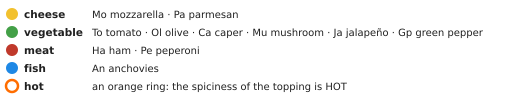

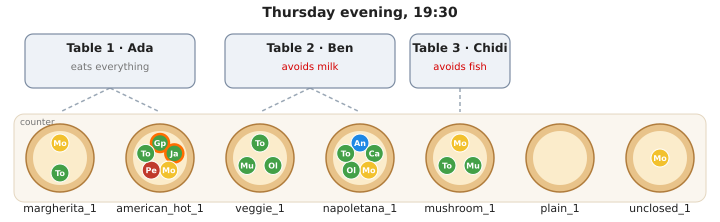

In [4]:
def picture(marked=(), violations=(), notes=(), warnings=(), title="", more_orders=()):
    # Draw the pizzeria; ring the marked objects, draw violations in red, write notes below the pizzas.
    kitchen = KitchenPicture(pizzas, orders + list(more_orders), marked=list(marked),
                             violations=list(violations), title=title)
    for pizza, text in notes:
        kitchen.note(pizza, text)
    for pizza, text in warnings:
        kitchen.note(pizza, text, Colour.WARNING)
    display(SVG(kitchen.to_svg()))


def rows_of(query):
    # The answers of a query, each as a tuple of the values of its selected variables.
    return [tuple(answer.values()) if isinstance(answer, dict) or hasattr(answer, "values") else (answer,)
            for answer in query.tolist()]


def show(title, query):
    # A question: print every answer and ring it in the picture.
    if query is ...:
        print(f"{title}: TODO")
        return
    rows = rows_of(query)
    print(f"{title}: {len(rows)} answer(s)")
    for row in rows:
        print("   ", row[0] if len(row) == 1 else row)
    picture(marked=[value for row in rows for value in row], title=title)


def refer(title, description):
    # A reference: the description must pick out exactly one object.
    if description is ...:
        print(f"{title}: TODO")
        return
    try:
        [(referent,)] = rows_of(description)
    except NoSolutionFound:
        print(f"{title}: nothing fits. The description does not refer.")
        return
    except MultipleSolutionFound:
        print(f"{title}: more than one object fits. The robot has to ask back.")
        return
    print(f"{title}: {referent}")
    picture(marked=[referent], title=title)


def check(title, constraint):
    # A constraint: every answer is a violation; the picture draws it in red.
    if constraint is ...:
        print(f"{title}: TODO")
        return
    rows = rows_of(constraint)
    if not rows:
        print(f"{title}: satisfied, no answer")
    for row in rows:
        print(f"{title}: VIOLATED by", row)
    violations = [(order, pizza) for row in rows for order in row if isinstance(order, Order)
                  for pizza in row if isinstance(pizza, Pizza)]
    picture(violations=violations, title=title)


display(SVG(legend_svg()))
picture(title="Thursday evening, 19:30")

This picture *is* an interpretation in the sense of Worksheet 2. Its domain is the set of objects; the
extension of `CheeseTopping` is the set of yellow dots; the extension of `hasTopping` is the set of pairs
(pizza, dot on that pizza). A query is evaluated *in* this one interpretation.

---
## Act 1 · Asking: *"Which pizzas have cheese?"*

The chef needs to know which pizzas have to go back into the oven for the cheese to melt.

### 1(a) A description is a concept

`a(Pizza)(...)` describes an object by its attributes; `.from_(pizzas)` says where to look. A nested
description on the list `toppings` means *some element* of the list fits. Compare with the concept
`Pizza ⊓ ∃hasTopping.CheeseTopping` of Worksheet 2.

cheesy pizzas: 5 answer(s)
    margherita_1
    napoletana_1
    american_hot_1
    mushroom_1
    unclosed_1


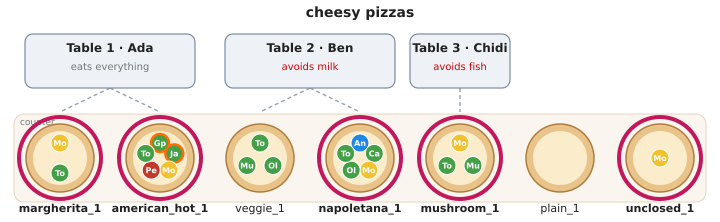

In [5]:
cheesy = a(Pizza)(toppings=a(CheeseTopping)()).from_(pizzas)
show("cheesy pizzas", cheesy)

The same question, written with variables. This is the first-order formula
`Pizza(p) ∧ ∃t (hasTopping(p, t) ∧ CheeseTopping(t))` almost symbol for symbol. The free variable `p` is
what is asked for.

| Description logic | First-order logic | EQL |
|:--|:--|:--|
| `Pizza` | `Pizza(p)` | `p = variable(Pizza, domain=pizzas)` |
| role filler | `hasTopping(p, t)` | `t = flat_variable(p.toppings)` |
| `∃hasTopping.C` | `∃t (hasTopping(p, t) ∧ C(t))` | `exists(t, HasType(t, C))` or `toppings=a(C)()` |
| `∀hasTopping.C` | `∀t (hasTopping(p, t) → C(t))` | `for_all(t, HasType(t, C))` |
| `¬`, `⊓`, `⊔` | `¬`, `∧`, `∨` | `not_(…)`, several conditions, `or_(…)` |

cheesy pizzas, with variables: 5 answer(s)
    margherita_1
    napoletana_1
    american_hot_1
    mushroom_1
    unclosed_1


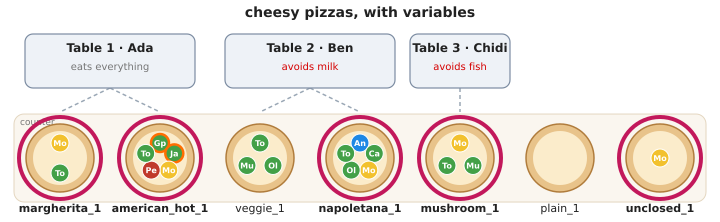

In [6]:
p = variable(Pizza, domain=pizzas)        # p ranges over the pizzas on the counter
t = flat_variable(p.toppings)             # t ranges over the toppings of p

show("cheesy pizzas, with variables", entity(p).where(exists(t, HasType(t, CheeseTopping))))

### 1(b) Some, only, none

**Predict** on the worksheet which pizzas each query returns, then run the cell. Watch `plain_1` (no
toppings) and `unclosed_1` (only mozzarella).

Q1  only vegetable toppings: 2 answer(s)
    veggie_1
    plain_1


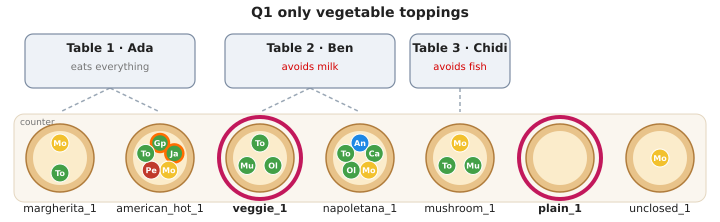

Q2  the toppings are [a mozzarella, a tomato]: 1 answer(s)
    margherita_1


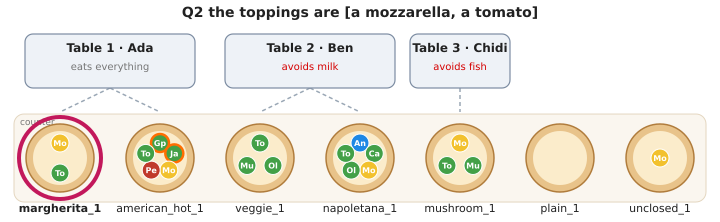

Q3  no cheese topping: 2 answer(s)
    veggie_1
    plain_1


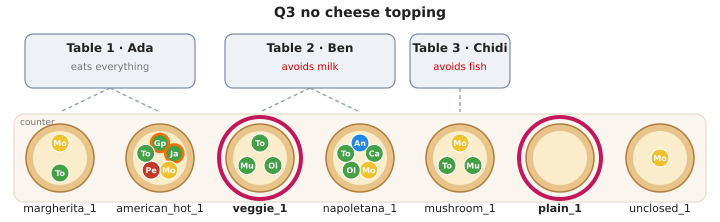

In [7]:
only_vegetables = entity(p).where(for_all(t, HasType(t, VegetableTopping)))
show("Q1  only vegetable toppings", only_vegetables)

exactly_these = a(Pizza)(toppings=[a(MozzarellaTopping)(), a(TomatoTopping)()]).from_(pizzas)
show("Q2  the toppings are [a mozzarella, a tomato]", exactly_these)

no_cheese = entity(p).where(not_(exists(t, HasType(t, CheeseTopping))))
show("Q3  no cheese topping", no_cheese)

**Solution note.** - **Q1** returns `veggie_1` and `plain_1`. `for_all` over an empty list is true (vacuous truth), exactly
  as p3 was in `∀hasTopping.VegetableTopping` last week.
- **Q2** returns only `margherita_1`. A *list* of descriptions describes the *whole* list: a mozzarella,
  then a tomato, nothing else. That is "some + only", the closure axiom of Worksheet 2, in one
  expression. `mushroom_1` has a third topping, `unclosed_1` only one.
- **Q3** returns `veggie_1` and `plain_1`. Nobody stated "veggie_1 has no cheese". The query concludes it
  because no cheese is in the list: negation as failure, the closed-world assumption.

**Your turn.** The menu marks the vegetarian pizzas. Write `vegetarian`: the pizzas with no meat topping
and no fish topping. Hint: *one* `exists` whose condition is an `or_(...)`.

vegetarian pizzas: 5 answer(s)
    margherita_1
    mushroom_1
    veggie_1
    plain_1
    unclosed_1


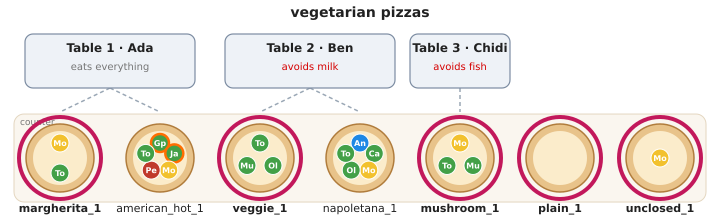

In [8]:
vegetarian = entity(p).where(
    not_(exists(t, or_(HasType(t, MeatTopping), HasType(t, FishTopping))))
)
show("vegetarian pizzas", vegetarian)

**Solution note.** Five pizzas: `margherita_1`, `mushroom_1`, `veggie_1`, `plain_1`, `unclosed_1`. In DL:
`Pizza ⊓ ¬∃hasTopping.(MeatTopping ⊔ FishTopping)`; by De Morgan the same as
`for_all(t, not_(or_(...)))`, i.e. `∀hasTopping.¬(MeatTopping ⊔ FishTopping)`. `unclosed_1` is in, unlike
last week in Protégé: the list is taken to be complete. Use one `exists`: two quantifiers that share `t`
would no longer be independent of each other. Two quantifiers need two `flat_variable(p.toppings)`.

### 1(c) Following the relations

Ada at table 1 does not like spicy food. She asks the robot: *"Is anything hot on my table?"* Descriptions
nest as deep as the objects do: an order has pizzas, a pizza has toppings, a topping has a spiciness.

**Your turn.** Write `hot_pizzas` (the pizzas with some topping whose spiciness is `Spiciness.HOT`) and
`hot_orders` (the orders with such a pizza).

hot pizzas: 1 answer(s)
    american_hot_1


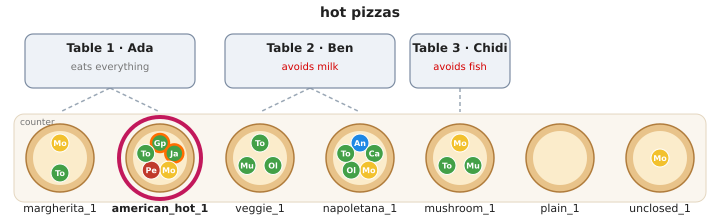

orders with a hot pizza: 1 answer(s)
    Order(table 1)


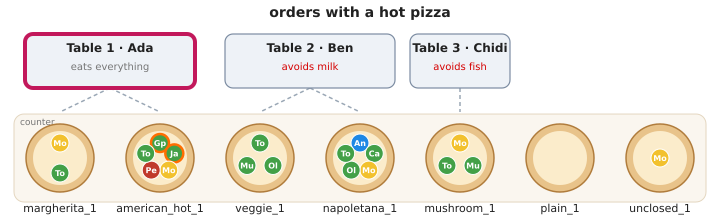

In [9]:
hot_pizzas = a(Pizza)(toppings=a(PizzaTopping)(spiciness=Spiciness.HOT)).from_(pizzas)
hot_orders = an(Order)(pizzas=a(Pizza)(toppings=a(PizzaTopping)(spiciness=Spiciness.HOT))).from_(orders)

show("hot pizzas", hot_pizzas)
show("orders with a hot pizza", hot_orders)

**Solution note.** `american_hot_1` and the order of table 1. In DL: `Pizza ⊓ ∃hasTopping.∃hasSpiciness.{Hot}`, and for the
order `∃hasPizza.∃hasTopping.∃hasSpiciness.{Hot}`. The American Hot has two hot toppings and is still
returned once: an object fits a description or it does not, however many witnesses there are.

Ada wants to know *what exactly* is hot. Now the robot does not ask *whether* there is a witness, it asks
for the witnesses themselves. With several variables, an answer is a **binding**: one value per variable,
such that the condition holds.

**Predict:** how many answers, and why not one?

who gets which hot topping: 2 answer(s)
    (Ada, american_hot_1, HotGreenPepperTopping)
    (Ada, american_hot_1, JalapenoPepperTopping)


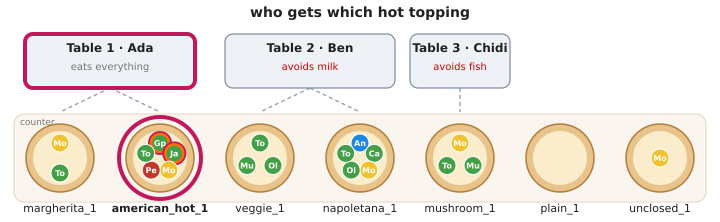

In [10]:
o = variable(Order, domain=orders)
ordered = flat_variable(o.pizzas)                 # a pizza of the order
topping = flat_variable(ordered.toppings)         # a topping of that pizza

show("who gets which hot topping", set_of(o.guest, ordered, topping).where(topping.spiciness == Spiciness.HOT))

**Solution note.** Two bindings: (Ada, american_hot_1, HotGreenPepperTopping) and (Ada, american_hot_1, JalapenoPepperTopping).
In logic: the formula `hasPizza(o, x) ∧ hasTopping(x, y) ∧ hasSpiciness(y, hot)` with the free variables
o, x, y has two satisfying assignments. `hot_orders` hid `x` and `y` under `∃`, so it only had one.

---
## Act 2 · Describing: *"Bring me the pizza with olives."*

The robot gets a command. Commands do not say *which object*; they *describe* it. `a(...)` means any
object that fits; `the(...)` claims that *exactly one* object fits, and fails otherwise.

### 2(a) *a* or *the*?

**Predict** what the robot does for each command, then run the cell.

the pizza with ham: nothing fits. The description does not refer.
the pizza with fish: napoletana_1


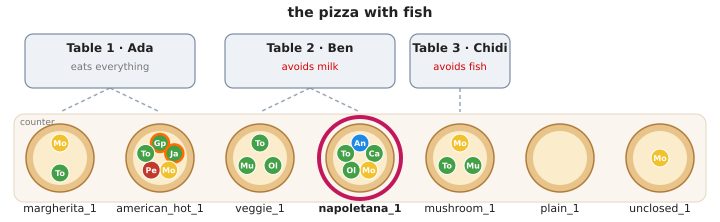

the pizza with olives: more than one object fits. The robot has to ask back.


In [11]:
refer("the pizza with ham", the(Pizza)(toppings=a(HamTopping)()).from_(pizzas))
refer("the pizza with fish", the(Pizza)(toppings=a(FishTopping)()).from_(pizzas))
refer("the pizza with olives", the(Pizza)(toppings=a(OliveTopping)()).from_(pizzas))

**Solution note.** Ham: no pizza fits (`NoSolutionFound`). Fish: `napoletana_1`. Olives: `napoletana_1` and `veggie_1` fit
(`MultipleSolutionFound`). A definite description presupposes that exactly one object fits (Russell).
If that is false, the command does not refer, and picking one at random would be a guess.

### 2(b) Making a description precise

The robot asks back: *"The one with fish or the one without?"* Ben answers: *"Without fish."*

**Your turn.** Write the description *"the pizza with olives and without fish"* so that `the` succeeds.
Two quantifiers need two variables over the toppings; `t2` is given.

the pizza with olives and without fish: veggie_1


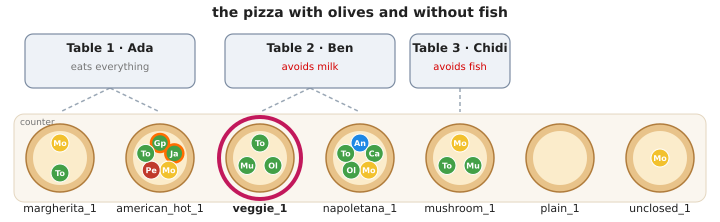

In [12]:
t2 = flat_variable(p.toppings)

olives_without_fish = the(entity(p).where(
    exists(t, HasType(t, OliveTopping)),
    not_(exists(t2, HasType(t2, FishTopping))),
))
refer("the pizza with olives and without fish", olives_without_fish)

**Solution note.** `veggie_1`. In DL: `Pizza ⊓ ∃hasTopping.OliveTopping ⊓ ¬∃hasTopping.FishTopping`, and its extension in
tonight's interpretation has exactly one element. The robot's question was chosen so that the answer
splits the candidates: a property that one has and the other has not. Finding such a property is again a
query over the candidates.

---
## Act 3 · Constraining: *"Ben must not get milk."*

Ben avoids milk. Nothing in the knowledge base says *"napoletana_1 contains milk"*. It has to be
computed: mozzarella is a cheese, cheese contains milk, the pizza has that topping.

### 3(a) Knowledge as a function

`symbolic_function` turns a Python function into vocabulary of the query language. Called on an object,
it returns its value; called on a variable, it becomes a condition that is evaluated for every binding.

on an object:   True
on a variable:  InstantiatedVariable - not a truth value but a piece of a query
vegetarian, with last week's function: 5 answer(s)
    margherita_1
    mushroom_1
    veggie_1
    plain_1
    unclosed_1


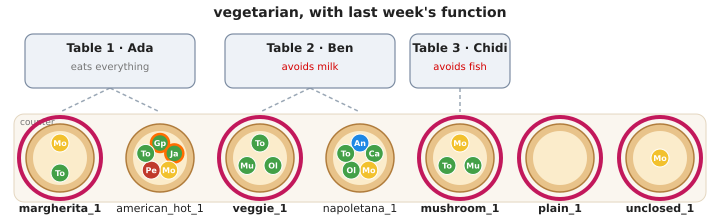

In [13]:
is_cheesy = symbolic_function(is_cheesy)
is_meaty = symbolic_function(is_meaty)
is_vegetarian = symbolic_function(is_vegetarian)

print("on an object:  ", is_vegetarian(margherita_1))
print("on a variable: ", type(is_vegetarian(p)).__name__, "- not a truth value but a piece of a query")
show("vegetarian, with last week's function", entity(p).where(is_vegetarian(p)))

**Your turn.** Complete `allergens`: a pizza with a cheese topping contains `Allergen.MILK`, a pizza with a
fish topping contains `Allergen.FISH`. Every pizza contains gluten, because of its base.

In [14]:
@symbolic_function
def allergens(pizza: Pizza) -> set[Allergen]:
    found = {Allergen.GLUTEN}
    if any(isinstance(topping, CheeseTopping) for topping in pizza.toppings):
        found.add(Allergen.MILK)
    if any(isinstance(topping, FishTopping) for topping in pizza.toppings):
        found.add(Allergen.FISH)
    return found


for pizza in pizzas:
    print(f"{pizza.name:16}", sorted(allergen.value for allergen in allergens(pizza)))

margherita_1     ['gluten', 'milk']
napoletana_1     ['fish', 'gluten', 'milk']
american_hot_1   ['gluten', 'milk']
mushroom_1       ['gluten', 'milk']
veggie_1         ['gluten']
plain_1          ['gluten']
unclosed_1       ['gluten', 'milk']


### 3(b) A relation that is computed, and a constraint

`hasTopping` is *stored*: it is the list `toppings`. *"Pizza x is safe for guest g"* is a relation as well,
but stored nowhere: it is computed from both. A `Predicate` is such a relation. Its fields are its
arguments, `__call__` decides whether it holds, and `_verbalization_fragment_` tells EQL how to say it in
English.

**Your turn.** Complete `__call__`: a pizza is safe for a guest if it contains none of the allergens the
guest avoids.

what can Ben eat?: 2 answer(s)
    veggie_1
    plain_1


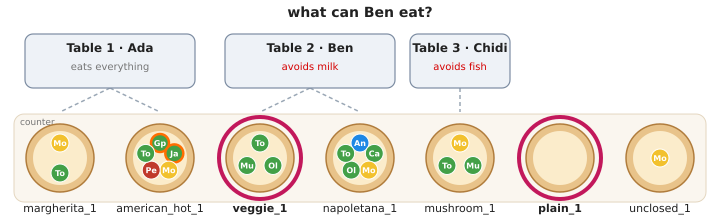

In [15]:
@dataclass(eq=False)
class IsSafeFor(Predicate):
    pizza: Pizza
    guest: Guest

    def __call__(self) -> bool:
        return not (allergens(self.pizza) & self.guest.avoids)

    @classmethod
    def _verbalization_fragment_(cls, fields):   # how EQL says it in English; do not edit
        return clause(Noun(fields["pizza"]), Copula(), Adjective("safe"), Prepositions.FOR, Noun(fields["guest"]))


show("what can Ben eat?", entity(p).where(IsSafeFor(p, ben)))

That was a *question*. The kitchen also needs a *rule that must never be broken*:

> Every pizza of an order is safe for the guest of that order.
> `∀o ∀x (hasPizza(o, x) → IsSafeFor(x, guest(o)))`

A query cannot *prove* a `∀`. It can search for a counterexample: `∃o ∃x (hasPizza(o, x) ∧ ¬IsSafeFor(…))`.
The constraint holds exactly when that query has **no** answer.

**Your turn.** Write `dangerous`: the pairs of an order and one of its pizzas that is not safe for the
guest of that order. Reuse `o` and `ordered` from Act 1. **Predict** the answer first.

every pizza is safe for its guest: VIOLATED by (Order(table 2), napoletana_1)


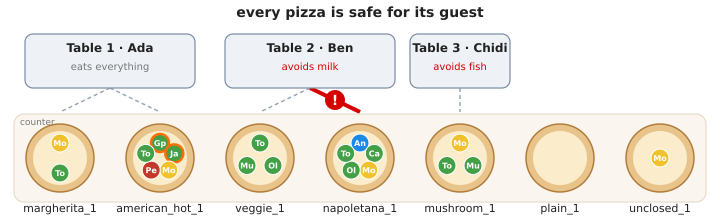

In [16]:
dangerous = set_of(o, ordered).where(not_(IsSafeFor(ordered, o.guest)))
check("every pizza is safe for its guest", dangerous)

**Solution note.** One violation: table 2, Ben, `napoletana_1` (mozzarella, so milk). The query does not only say *that*
the constraint is broken, the binding says *where*: the robot knows which plate not to serve. `o.guest`
is a path from the order to its guest: a relation followed, not a join written.

---
## Act 4 · Inferring: *the kitchen writes warnings and labels*

### 4(a) A rule creates facts

The predicate of Act 3 computes its answer every time it is asked. A **rule** writes its conclusion down
as new objects that later queries can use. `inference(AllergenWarning)(...)` creates one warning for
every object that fits the description inside it: the description is the body of the rule, the new
object its head.

> `∀x (Pizza(x) ∧ ∃y (hasTopping(x, y) ∧ CheeseTopping(y)) → ∃w (Warning(w) ∧ about(w, x) ∧ allergen(w, milk)))`

**Your turn.** The milk rule is given. Write the rule for fish, and the rule that *every* pizza carries a
gluten warning (a rule without a condition: use the variable `p`). **Predict** the number of warnings.

13 warnings


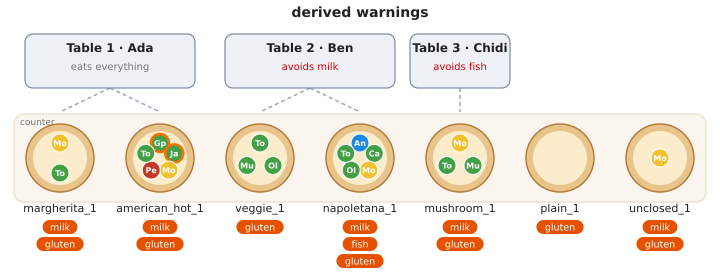

In [17]:
@dataclass(eq=False, repr=False)
class AllergenWarning:
    pizza: Pizza
    allergen: Allergen

    def __repr__(self):
        return f"Warning({self.pizza}: {self.allergen.value})"


milk_warnings = inference(AllergenWarning)(pizza=cheesy, allergen=Allergen.MILK).tolist()

fishy = a(Pizza)(toppings=a(FishTopping)()).from_(pizzas)
fish_warnings = inference(AllergenWarning)(pizza=fishy, allergen=Allergen.FISH).tolist()
gluten_warnings = inference(AllergenWarning)(pizza=p, allergen=Allergen.GLUTEN).tolist()

warnings = milk_warnings + fish_warnings + gluten_warnings
print(len(warnings), "warnings")
picture(warnings=[(warning.pizza, warning.allergen.value) for warning in warnings], title="derived warnings")

**Solution note.** 13 warnings: 5 milk, 1 fish, 7 gluten. The warnings are objects now, part of the knowledge base, and
could be queried, counted or joined like pizzas. Producing all conclusions in advance is *forward
chaining* (materialisation); it is what HermiT did when it filled the inferred class hierarchy.

### 4(b) Rules with exceptions

The menu needs a label for each pizza. The chef's rule of thumb:

> A pizza without meat and fish is **vegetarian**, *unless* it has no cheese either: then it is
> **vegan**. *Otherwise*, if it has meat, it is **meaty**.

A rule tree states exactly this. Inside `with query:` the first `add` is the default conclusion,
`refinement(condition)` is the *unless* (it replaces the conclusion where the condition also holds), and
`alternative(condition)` is the *otherwise* (tried where the query's own condition fails).

**Predict** the label of each pizza on the worksheet, then run the cell.

[Vegetarian(margherita_1), Meaty(american_hot_1), Vegetarian(mushroom_1), Vegan(veggie_1), Vegan(plain_1), Vegetarian(unclosed_1)]


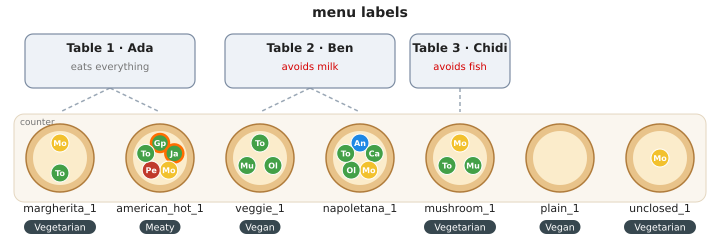

In [18]:
@dataclass(eq=False, repr=False)
class Label:
    pizza: Pizza

    def __repr__(self):
        return f"{type(self).__name__}({self.pizza})"

class Vegetarian(Label): ...
class Vegan(Label): ...
class Meaty(Label): ...


def label_pizzas():
    label = deduced_variable(Label)
    query = entity(label).where(is_vegetarian(p))
    with query:
        add(label, inference(Vegetarian)(pizza=p))
        with refinement(not_(is_cheesy(p))):
            add(label, inference(Vegan)(pizza=p))
        with alternative(is_meaty(p)):
            add(label, inference(Meaty)(pizza=p))
    return query.tolist()


labels = label_pizzas()
print(labels)
picture(notes=[(label.pizza, type(label).__name__) for label in labels], title="menu labels")

**Solution note.** Vegetarian: `margherita_1`, `mushroom_1`, `unclosed_1`. Vegan: `veggie_1`, `plain_1`. Meaty:
`american_hot_1`. **No label:** `napoletana_1`: it has fish, so it is not vegetarian, and no meat, so the
alternative does not apply. The rules are *silent* about it. Silence is not "no": they never concluded
"not vegetarian". The refinement is an *exception*: the general conclusion is replaced where a more
specific one applies. Trees of this shape are called ripple-down rules.

### 4(c) The world moves on

It is busy. The cook mixes up two tickets and grates parmesan over `veggie_1`, the pizza for Ben.

**Predict** what each of the three outputs says, then run the cell. Which of them protects Ben?

1. the constraint of Act 3, evaluated now: VIOLATED by (Order(table 2), veggie_1)
1. the constraint of Act 3, evaluated now: VIOLATED by (Order(table 2), napoletana_1)


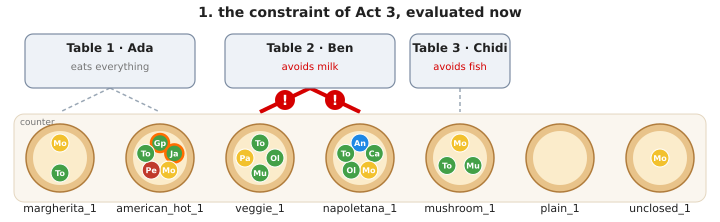

2. milk warnings, derived in 4(a): [Warning(margherita_1: milk), Warning(napoletana_1: milk), Warning(american_hot_1: milk), Warning(mushroom_1: milk), Warning(unclosed_1: milk)]
3. the label of veggie_1, derived again: [Vegetarian(veggie_1)]


In [19]:
veggie_1.toppings.append(ParmesanTopping())

check("1. the constraint of Act 3, evaluated now", dangerous)
print("2. milk warnings, derived in 4(a):", milk_warnings)
print("3. the label of veggie_1, derived again:", [label for label in label_pizzas() if label.pizza is veggie_1])

**Solution note.** 1. The constraint now reports **two** violations: `napoletana_1` and `veggie_1`. It was written long
   before the parmesan; it is evaluated against the state of the world at the moment it is asked.
2. The milk warnings do not mention `veggie_1`. They were concluded at a fixed moment and are stale now,
   until the rule runs again. Deciding *when* to re-derive is the hard part of forward chaining.
3. `veggie_1` was `Vegan`, now it is `Vegetarian`. A new fact *removed* a conclusion: the reasoning is
   **non-monotonic**. Classical logic and OWL are monotonic: what is entailed stays entailed when axioms
   are added. Under the open-world assumption OWL would never have concluded "vegan" in the first place.

the constraint, after the new veggie_1: VIOLATED by (Order(table 2), napoletana_1)


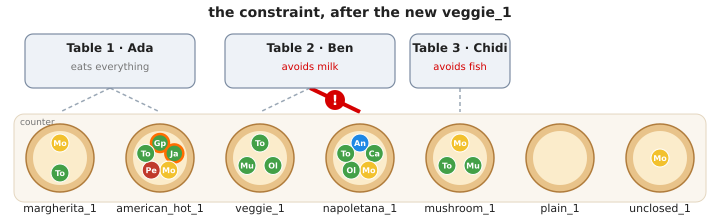

In [20]:
veggie_1.toppings.pop()   # the cook bakes Ben a new veggie_1
check("the constraint, after the new veggie_1", dangerous)

---
## Act 5 · One description, many ways to answer it

Dana sits down at table 4 and orders *"a pizza with mozzarella and tomato, nothing else"*. That is a
description, exactly like those of Act 1. What changes is *who answers it*. A query is a symbolic object;
a **backend** is something that answers it. The same description can be answered by different backends:

In [21]:
wish = a(Pizza)(toppings=[a(MozzarellaTopping)(), a(TomatoTopping)()])

on_the_counter = list(EntityQueryLanguageBackend().evaluate(wish.from_(pizzas)))
print("selected from the counter:", on_the_counter)

from_the_kitchen = list(EntityQueryLanguageGenerativeBackend().evaluate(wish))
print("made by the kitchen:      ", from_the_kitchen, from_the_kitchen[0].toppings)

selected from the counter: [margherita_1]
made by the kitchen:       [a new pizza] [MozzarellaTopping, TomatoTopping]


A description usually leaves things open. Dana adds: *"and a green pepper, I don't mind how hot"*. `...`
marks what she left open. **Predict:** how many pizzas fit this description?

a new pizza [(MozzarellaTopping, 'MILD'), (HotGreenPepperTopping, 'MILD')]
a new pizza [(MozzarellaTopping, 'MILD'), (HotGreenPepperTopping, 'MEDIUM')]
a new pizza [(MozzarellaTopping, 'MILD'), (HotGreenPepperTopping, 'HOT')]


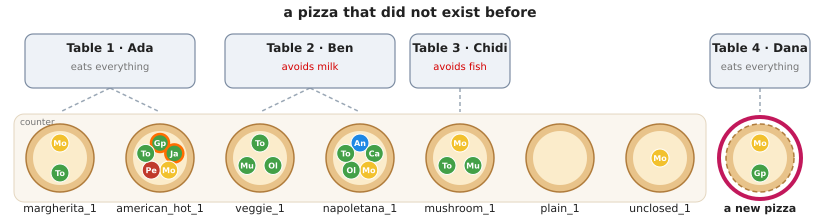

In [22]:
open_wish = a(Pizza)(toppings=[a(MozzarellaTopping)(), a(HotGreenPepperTopping)(spiciness=...)])

candidates = list(EntityQueryLanguageGenerativeBackend().evaluate(open_wish))
for candidate in candidates:
    print(candidate, [(topping, topping.spiciness.name) for topping in candidate.toppings])

dana = Guest("Dana")
picture(marked=candidates[:1], more_orders=[Order(4, dana, candidates[:1])],
        title="a pizza that did not exist before")

**Solution note.** Three pizzas, one per spiciness: the description has three *models* over this domain, and the generator
constructs them. In Act 1 the description *selected* among existing objects; here it is a
*specification*, and the answers are new objects. Act 5(b) on the worksheet goes one step further: a
robot plan whose open slots are answered by different backends.

---
## The whole picture

Everything the robot found out tonight, in one picture: the answers to the chef's question (Act 1), the
violated constraint (Act 3), and the conclusions of the rules (Act 4).

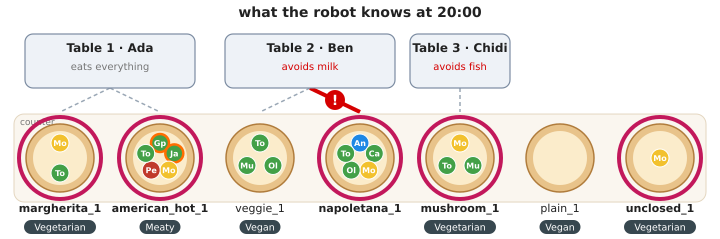

In [23]:
violations = [] if dangerous is ... else [(order, pizza) for order, pizza in rows_of(dangerous)]
picture(marked=cheesy.tolist(), violations=violations,
        notes=[(label.pizza, type(label).__name__) for label in label_pizzas()],
        title="what the robot knows at 20:00")